<a href="https://colab.research.google.com/github/Amyerm/ClassFiles/blob/main/PracticaRegresionLinealMultiple.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Maestría en Inteligencia Artificial y Analítica de Datos

## Programación para Analítica Descriptiva y Predictiva - Marzo 2025
## Práctica: Práctica: Regresión Lineal Múltiple
---


## Datos del Estudiante

*   Apellidos y Nombre: Ari Daniel Mendoza Enrriquez
*   Matrícula: 271756

---



##  Objetivo de aprendizaje
Al finalizar esta práctica, el estudiante será capaz de **aplicar regresión lineal múltiple utilizando Scikit-Learn para modelar la relación entre varias variables independientes y una variable dependiente**, verificar los supuestos del modelo, interpretar los coeficientes, analizar la correlación entre predictores y evaluar el rendimiento del modelo utilizando métricas como el MSE, RMSE y R².

Datos
Trabajarás con el archivo `advertising.csv`, que contiene información sobre el gasto publicitario en diferentes medios y las ventas obtenidas:

-`TV`: inversión en publicidad televisiva.

-`Radio`: inversión en publicidad en radio.

-`Newspaper`: inversión en publicidad en periódicos.

`Sales`: ventas del producto (variable dependiente).

## Parte 1: Carga de datos y bibliotecas
1. Importa las bibliotecas necesarias.
2. Carga el archivo `advertising.csv`.
3. Muestra las primeras filas del dataframe.
4. Describe estadísticamente las variables.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
import scipy.stats as stats

df = pd.read_csv("advertising.csv")

df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


In [3]:
df.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


## Parte 2: Análisis exploratorio de los datos
### 2.1  Análisis de la Relación Lineal entre la variable dependiente y las independientes
1. Grafica dispersión entre cada variable independiente (`TV`, `Radio`, `Newspaper`) y `Sales`. Usa también regplot.
2. Interpreta visualmente la relación entre variables.

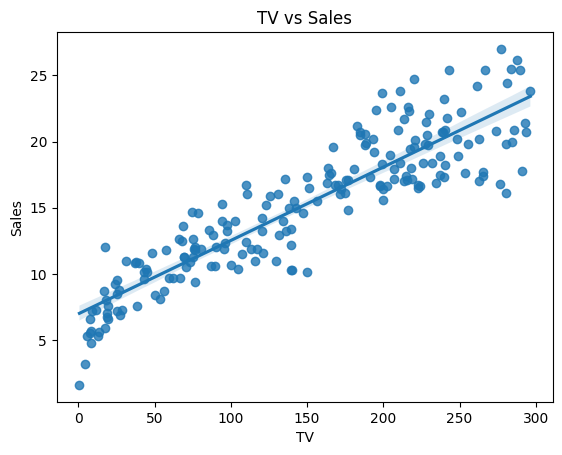

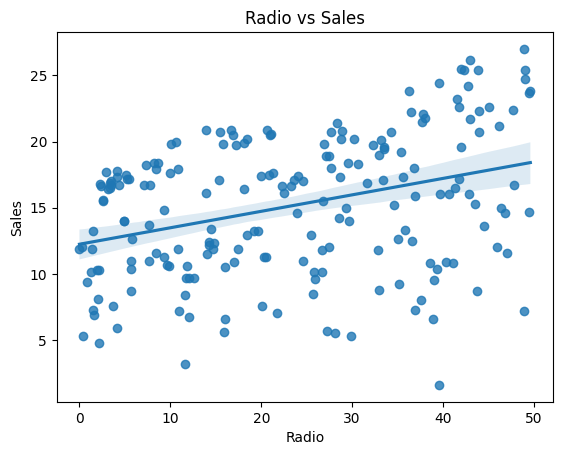

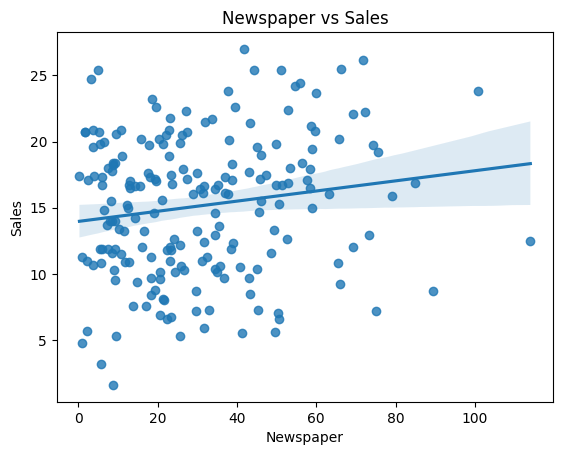

In [4]:
# Gráficos de dispersión

sns.regplot(x="TV", y="Sales", data=df)
plt.title("TV vs Sales")
plt.show()

sns.regplot(x="Radio", y="Sales", data=df)
plt.title("Radio vs Sales")
plt.show()

sns.regplot(x="Newspaper", y="Sales", data=df)
plt.title("Newspaper vs Sales")
plt.show()

Se observa que TV tiene una relación positiva fuerte con Sales, conforme aumenta la inversión en televisión también aumentan las ventas. Radio también presenta una relación positiva, aunque es menos marcada y existe mayor dispersión entre los datos. Newspaper muestra una relación mucho más débil con las ventas, los puntos se encuentran bastante dispersos y no siguen una tendencia tan clara.

### 2.2: Correlación entre variables
1. Calcula la matriz de correlación.
2. Visualízala con un heatmap.
3. Responde: ¿Qué variables están más correlacionadas con `Sales`? ¿Hay correlación alta entre predictores?

                 TV     Radio  Newspaper     Sales
TV         1.000000  0.054809   0.056648  0.901208
Radio      0.054809  1.000000   0.354104  0.349631
Newspaper  0.056648  0.354104   1.000000  0.157960
Sales      0.901208  0.349631   0.157960  1.000000


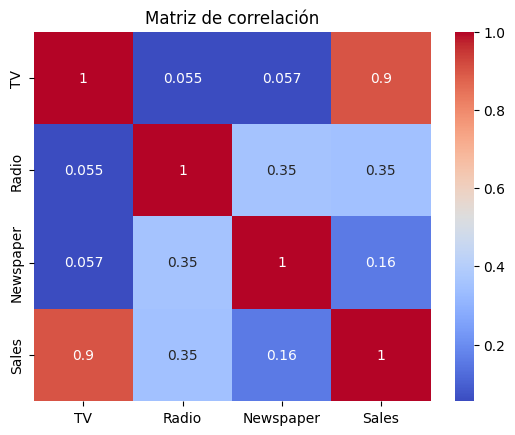

In [5]:
# Correlación y heatmap

correlacion = df.corr()

print(correlacion)

sns.heatmap(correlacion, annot=True, cmap="coolwarm")
plt.title("Matriz de correlación")
plt.show()

La variable que tiene mayor correlación con Sales es TV, con un valor aproximado de 0.90. Radio presenta una correlación positiva menor, de aproximadamente 0.35, mientras que Newspaper tiene una correlación débil, cercana a 0.16. Entre las variables independientes no se observan correlaciones altas, por lo que no parece existir un problema importante de relación entre los predictores.

## Parte 3. Multicolinealidad
1. Calcula el VIF (Variance Inflation Factor) para cada predictor.
2. Crea un diagrama de barras  para mostrar el  VIF
3. Interpreta si hay multicolinealidad:
- ¿Alguna variable tiene un VIF mayor a 5 o mayor a 10?
- ¿Qué implicaciones tiene esto para el modelo?

    Variable       VIF
0         TV  1.004611
1      Radio  1.144952
2  Newspaper  1.145187


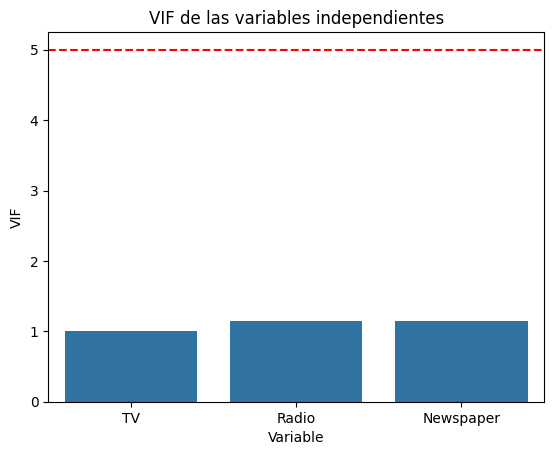

In [6]:
# Multicolinealidad

X = df[["TV", "Radio", "Newspaper"]]

vif = pd.DataFrame()
vif["Variable"] = X.columns
vif["VIF"] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

print(vif)

sns.barplot(x="Variable", y="VIF", data=vif)
plt.title("VIF de las variables independientes")
plt.axhline(y=5, color="red", linestyle="--")
plt.show()

Ninguna de las variables presenta un VIF mayor a 5 ni a 10. Los valores obtenidos están cercanos a 1, por lo que no se observa un problema importante de multicolinealidad. Esto indica que las variables independientes no tienen una relación lineal fuerte entre sí y pueden mantenerse en el modelo sin afectar de manera importante la estabilidad de los coeficientes.

## Parte 4: Construcción del Modelo (Todas las variables Independientes), Evaluación

### 4.1 Entrenamiento del Modelo (Todas las Variables Independientes)

1. Entrena un modelo de regresión lineal múltiple usando TV, Radio y Newspaper como variables independientes.
2. Imprime el intercepto y los coeficientes del modelo.
3. Interpreta cada uno:
¿Qué significa cada uno de los coeficientes  en términos de ventas?

In [7]:
# Entrenamiento del Modelo (Todas las Variables Independientes)

X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]

modelo = LinearRegression()
modelo.fit(X, y)

print("Intercepto:", modelo.intercept_)

coeficientes = pd.DataFrame({
    "Variable": X.columns,
    "Coeficiente": modelo.coef_
})

coeficientes

Intercepto: 4.625124078808653


,Variable,Coeficiente
0,TV,0.054446
1,Radio,0.107001
2,Newspaper,0.000336


El intercepto indica que, si la inversión en TV, Radio y Newspaper fuera igual a cero, las ventas estimadas serían de aproximadamente 4.63 unidades. Manteniendo las demás variables constantes, por cada unidad adicional de inversión en TV las ventas aumentan aproximadamente 0.054 unidades, mientras que por cada unidad adicional en Radio aumentan cerca de 0.107 unidades. En el caso de Newspaper, el coeficiente es muy cercano a cero, por lo que su efecto sobre las ventas parece ser prácticamente nulo.

### 4.2 Normalidad de los residuos

1. Calcula los residuos: residuos = y - y_pred.

2. Grafica un histograma con KDE de los residuos.

3. ¿Los residuos parecen distribuirse normalmente?

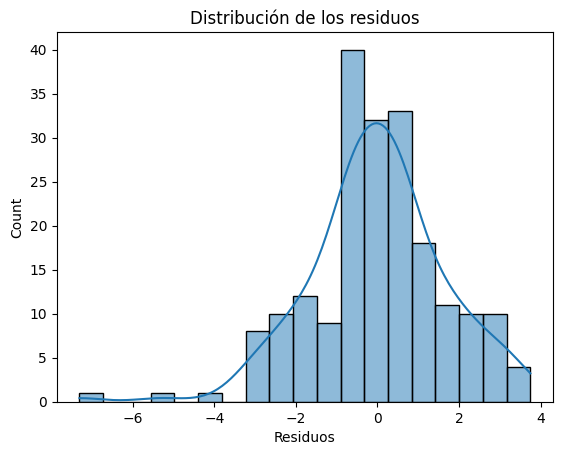

In [8]:
# Normalidad de los residuos

y_pred = modelo.predict(X)
residuos = y - y_pred

sns.histplot(residuos, kde=True)
plt.title("Distribución de los residuos")
plt.xlabel("Residuos")
plt.show()

Los residuos se concentran alrededor de cero y presentan una forma aproximadamente similar a una distribución normal. Se observan algunos valores negativos alejados del centro, por lo que existe una ligera desviación en la cola izquierda. En general, la distribución es razonablemente cercana a la normalidad.

### 4.3. Homocedasticidad

1. Grafica los residuos contra los valores predichos.
2. ¿Observas patrones? ¿Los residuos se dispersan aleatoriamente?

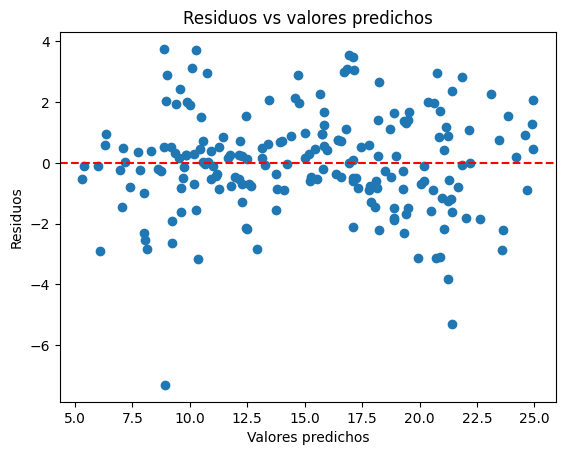

In [9]:
# Homocedasticidad

plt.scatter(y_pred, residuos)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Valores predichos")
plt.ylabel("Residuos")
plt.title("Residuos vs valores predichos")
plt.show()

Los residuos se encuentran distribuidos alrededor de la línea de cero y no se observa un patrón muy definido. La dispersión no es completamente uniforme y se presentan algunos valores atípicos. El supuesto de homocedasticidad parece cumplirse de manera aproximada, aunque no de forma perfecta.

### 4.4 Q-Q Plot

1. Graficar el Q-Q Plot
2. Interpreta el gráfico: a) Si los puntos se alinean aproximadamente sobre la línea diagonal, los residuos siguen una distribución normal, b) Desviaciones sistemáticas indican asimetría o colas pesadas.

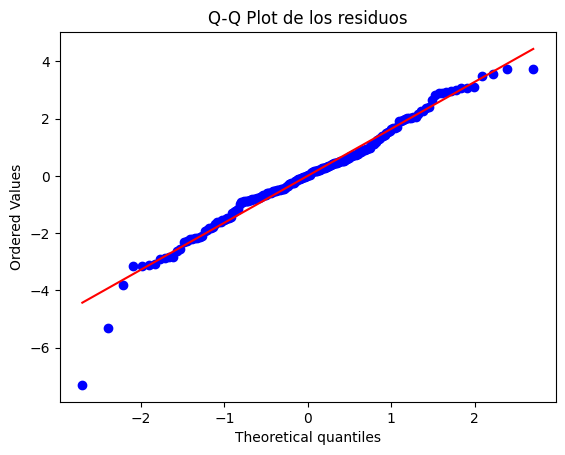

In [10]:
# Q-Q Plot

stats.probplot(residuos, dist="norm", plot=plt)
plt.title("Q-Q Plot de los residuos")
plt.show()

La mayoría de los puntos se encuentran cerca de la línea diagonal, por lo que los residuos siguen aproximadamente una distribución normal. Sin embargo, en los extremos se observan algunas desviaciones, especialmente en la cola izquierda, donde aparecen algunos valores alejados de la línea. Esto indica que la normalidad se cumple de manera aproximada, aunque existen algunos valores atípicos.

### 4.5. Evaluación del Modelo

1. Calcula las métricas: a) MSE (error cuadrático medio), b) RMSE (raíz del error cuadrático medio), c) R² (coeficiente de determinación)

2. ¿Qué nos dicen estas métricas sobre el ajuste del modelo?


In [11]:
# Evaluación del Modelo

mse = mean_squared_error(y, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y, y_pred)

print("MSE:", mse)
print("RMSE:", rmse)
print("R²:", r2)

MSE: 2.706006147627315
RMSE: 1.6449942697855562
R²: 0.9025912899684558


El modelo presenta un buen ajuste sobre los datos analizados. El R² es aproximadamente 0.90, lo que indica que cerca del 90.3% de la variación de las ventas es explicada por las variables TV, Radio y Newspaper. El MSE es de aproximadamente 2.71 y el RMSE de 1.65, lo que indica una magnitud de error relativamente baja entre los valores reales y los predichos. En general, estas métricas muestran que el modelo se ajusta bien a los datos.

### 4.6. Visualización de Predicciones

1. Crea un gráfico comparando Sales reales vs Sales predichas.

2. Puedes usar plt.scatter(y_true, y_pred) para evaluar visualmente el ajuste.
3.¿Qué observas?¿Qué observas? ¿Qué información puedes obtener de esta gráfica?

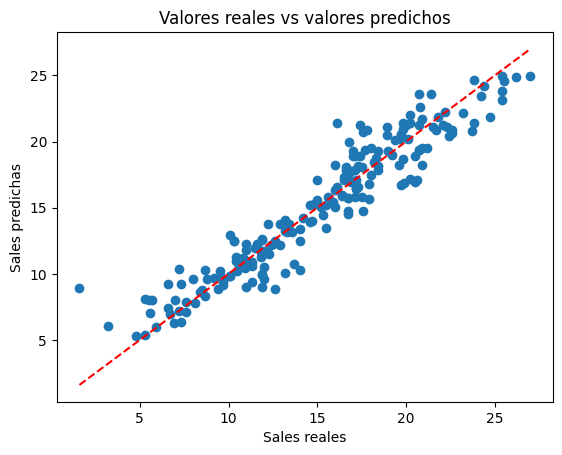

In [12]:
# Visualización de las Predicciones

plt.scatter(y, y_pred)
plt.xlabel("Sales reales")
plt.ylabel("Sales predichas")
plt.title("Valores reales vs valores predichos")

plt.plot([y.min(), y.max()], [y.min(), y.max()], color="red", linestyle="--")

plt.show()

La mayoría de los puntos se encuentran cerca de la línea diagonal, las predicciones del modelo son bastante cercanas a los valores reales. Se observan algunos puntos más alejados, lo que indica que existen ciertos errores de predicción, el ajuste visual es bueno. La gráfica permite identificar qué tan cerca están las ventas predichas de las ventas reales.

### 4.7 Verificar el impacto de los atributos en el modelo

1. Ajusta el modelo usando statsmodels en lugar de scikit-learn para obtener los valores p.
2. Interpreta los resultados:

 - Observa los valores P>|t| en la tabla de salida.

 - ¿Qué variables tienen p-value menores a 0.05?

 - ¿Cuál es la conclusión sobre esas variables?


In [13]:
# P-values

X_sm = sm.add_constant(X)

modelo_sm = sm.OLS(y, X_sm).fit()

print(modelo_sm.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.901
Method:                 Least Squares   F-statistic:                     605.4
Date:                Fri, 30 Oct 2026   Prob (F-statistic):           8.13e-99
Time:                        01:50:38   Log-Likelihood:                -383.34
No. Observations:                 200   AIC:                             774.7
Df Residuals:                     196   BIC:                             787.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6251      0.308     15.041      0.0

Al observar los valores P>|t|, TV y Radio presentan p-values menores a 0.05, por lo que se consideran variables estadísticamente significativas para explicar las ventas. Newspaper tiene un p-value de aproximadamente 0.954, que es mucho mayor a 0.05. Esto indica que Newspaper no presenta un efecto significativo sobre Sales cuando se consideran también TV y Radio en el modelo.

##Parte 5:  Construcción del Modelo (sin Multicolinealidad), Evaluación

En el caso de que hayas detectado variables con multicolinealidad. Elimina aquellas que presenten esta característica y realiza los mismos pasos** que la parte 4.**
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

En la Parte 3 no se detectaron variables con problemas de multicolinealidad, ya que todos los valores de VIF fueron menores a 5. Por esta razón, no es necesario eliminar ninguna variable por este criterio y el modelo sin multicolinealidad sería el mismo que el construido en la Parte 4.

## Parte 6: Construcción del Modelo (sin variables que no muestran una relación lineal), Evaluación

En el caso de que hayas detectado variables sin una relación lineal con la variable dependiente. Elimina aquellas que presenten esta característica y realiza lo siguiente.

En el caso de que hayas detectado variables sin una relación lineal. Elimina aquellas que presenten esta característica y realiza los mismos pasos** que la parte 4.**
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

In [14]:
# Entrenamiento del modelo sin Newspaper

X2 = df[["TV", "Radio"]]
y2 = df["Sales"]

modelo2 = LinearRegression()
modelo2.fit(X2, y2)

print("Intercepto:", modelo2.intercept_)

coeficientes2 = pd.DataFrame({
    "Variable": X2.columns,
    "Coeficiente": modelo2.coef_
})

coeficientes2

Intercepto: 4.630879464097768


,Variable,Coeficiente
0,TV,0.054449
1,Radio,0.107175


Para este modelo se eliminó Newspaper debido a que mostró una relación débil con Sales y anteriormente no resultó estadísticamente significativa.

El intercepto indica que, si la inversión en TV y Radio fuera igual a cero, las ventas estimadas serían de aproximadamente 4.63 unidades. Manteniendo la otra variable constante, por cada unidad adicional de inversión en TV las ventas aumentan aproximadamente 0.054 unidades. En Radio, por cada unidad adicional de inversión las ventas aumentan cerca de 0.107 unidades.

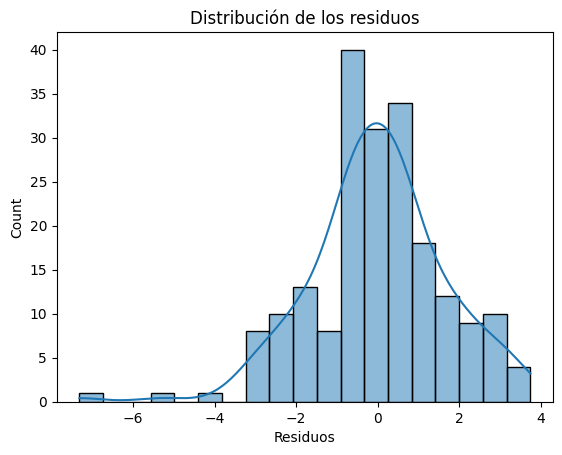

In [15]:
#Normalidad de los residuos
y_pred2 = modelo2.predict(X2)
residuos2 = y2 - y_pred2

sns.histplot(residuos2, kde=True)
plt.title("Distribución de los residuos")
plt.xlabel("Residuos")
plt.show()

Los residuos se concentran alrededor de cero y presentan una forma aproximadamente normal. Sin embargo, se observan algunos valores negativos alejados del centro, por lo que existe una ligera desviación en la cola izquierda. La distribución de los residuos es razonablemente cercana a la normalidad.

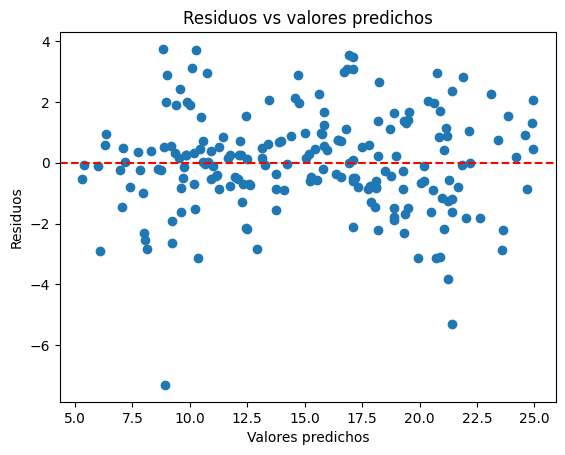

In [16]:
#Homocedasticidad
plt.scatter(y_pred2, residuos2)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Valores predichos")
plt.ylabel("Residuos")
plt.title("Residuos vs valores predichos")
plt.show()

Los residuos se distribuyen alrededor de la línea de cero y no se observa un patrón definido. La dispersión no es completamente uniforme y existen algunos valores atípicos, el supuesto de homocedasticidad parece cumplirse de manera aproximada.

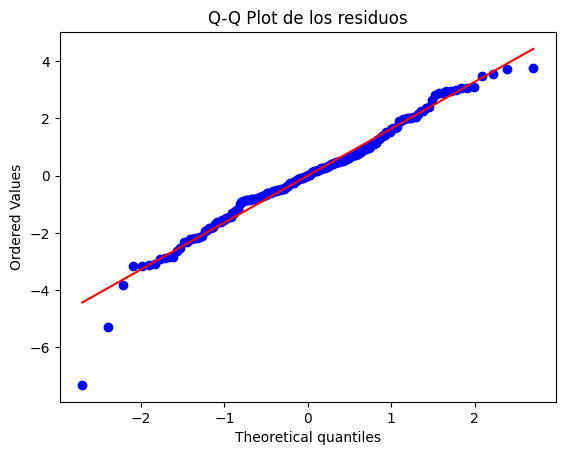

In [17]:
#Q-Q Plot
stats.probplot(residuos2, dist="norm", plot=plt)
plt.title("Q-Q Plot de los residuos")
plt.show()

La mayoría de los puntos se encuentran cerca de la línea diagonal, por lo que los residuos siguen aproximadamente una distribución normal. Se observan algunas desviaciones en los extremos, especialmente en la cola izquierda. Esto indica que la normalidad se cumple de manera aproximada, aunque existen algunos valores atípicos.

In [18]:
#Evaluación del Modelo
mse2 = mean_squared_error(y2, y_pred2)
rmse2 = np.sqrt(mse2)
r2_2 = r2_score(y2, y_pred2)

print("MSE:", mse2)
print("RMSE:", rmse2)
print("R²:", r2_2)

MSE: 2.7060525778834883
RMSE: 1.6450083823140502
R²: 0.9025896186081139


El modelo mantiene un buen ajuste después de eliminar Newspaper. El R² sigue siendo aproximadamente 0.90, por lo que explica cerca del 90.3% de la variación de las ventas. El RMSE es de aproximadamente 1.65, muy similar al del modelo anterior. Esto indica que eliminar Newspaper prácticamente no afecta el desempeño del modelo.

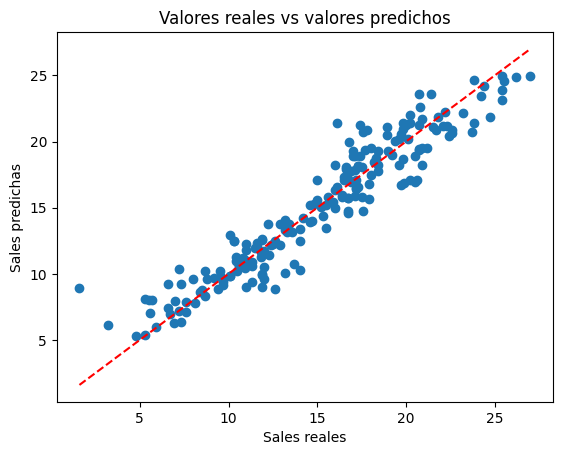

In [19]:
#Visualización de Predicciones
# Visualización de las Predicciones

plt.scatter(y2, y_pred2)
plt.xlabel("Sales reales")
plt.ylabel("Sales predichas")
plt.title("Valores reales vs valores predichos")

plt.plot(
    [y2.min(), y2.max()],
    [y2.min(), y2.max()],
    color="red",
    linestyle="--"
)

plt.show()

La mayoría de los puntos se encuentran cerca de la línea diagonal, por lo que las ventas predichas son bastante similares a las ventas reales. Se observan algunos puntos más alejados, pero en general el ajuste visual sigue siendo bueno. Esto confirma que eliminar Newspaper no afecta de forma importante la capacidad del modelo para realizar predicciones.

In [20]:
#Verificar el impacto de los atributos en el modelo
# P-values del modelo sin Newspaper

X2_sm = sm.add_constant(X2)

modelo2_sm = sm.OLS(y2, X2_sm).fit()

print(modelo2_sm.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.902
Method:                 Least Squares   F-statistic:                     912.7
Date:                Fri, 30 Oct 2026   Prob (F-statistic):          2.39e-100
Time:                        01:50:39   Log-Likelihood:                -383.34
No. Observations:                 200   AIC:                             772.7
Df Residuals:                     197   BIC:                             782.6
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6309      0.290     15.952      0.0

Al observar los valores P>|t|, tanto TV como Radio tienen p-values menores a 0.05. Esto indica que ambas variables son estadísticamente significativas para explicar las ventas y aportan información útil al modelo. Por lo tanto, las dos pueden mantenerse como predictores de Sales.

##7. Conclusiones.

¿Cuál de los tres modelos construidos fue el mejor?
¿Cuál fue el atributo que mas influencia tiene en las ventas?

El modelo que utiliza únicamente TV y Radio se puede considerar el mejor, ya que obtuvo prácticamente el mismo desempeño que el modelo con las tres variables, con un R² cercano a 0.90, pero utiliza menos predictores. Además, Newspaper presentó una relación débil con Sales y un p-value mayor a 0.05, por lo que no aportaba de manera significativa al modelo.

La variable que mostró la relación más fuerte con las ventas fue TV, con una correlación aproximada de 0.90. Radio también resultó estadísticamente significativa, mientras que Newspaper no mostró un efecto significativo. Por estas razones, el modelo con TV y Radio es más sencillo y mantiene prácticamente la misma capacidad para explicar las ventas.